In [220]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error, make_scorer, mean_absolute_percentage_error
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, cross_validate
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Model with VAC features

In [221]:
df = pd.read_csv("../data/result_with_vac.csv")
df.head()

,title,x,y,B,dB_dx,dB_dy,Jc,Jx,Jy,Ic,Rn,n
0,1,-0.01,0.0,-0.000325,-0.12875,-0.0760,1.090335e+08,7.915898e+07,7.498113e+07,NaN,NaN,NaN
1,1,0.79,0.0,-0.000401,-0.22875,-0.0965,9.263875e+07,8.640185e+06,9.223495e+07,NaN,NaN,NaN
2,1,1.59,0.0,-0.000518,-0.36750,-0.1235,4.150431e+07,3.640487e+07,1.993222e+07,NaN,NaN,NaN
3,1,2.39,0.0,-0.000648,-0.49875,-0.1220,4.602157e+08,-4.334496e+08,-1.546606e+08,NaN,NaN,NaN
4,1,3.19,0.0,-0.000762,-0.70125,-0.0860,1.537920e+09,-1.537311e+09,-4.328145e+07,NaN,NaN,NaN


In [222]:
unique_titles = df['title'].unique()

train_val_titles, test_titles = train_test_split(
    unique_titles, test_size=0.15, random_state=42
)

train_titles, val_titles = train_test_split(
    train_val_titles, test_size=0.1765, random_state=42
)

In [223]:
df['log_Jc'] = np.log10(df['Jc'].replace(0, np.nan))
df_train = df[df['title'].isin(train_titles)].copy()
df_val = df[df['title'].isin(val_titles)].copy()
df_test = df[df['title'].isin(test_titles)].copy()

In [224]:
print(f"Train: {df_train['title'].nunique()} samples, {len(df_train)} rows")
print(f"Validation: {df_val['title'].nunique()} samples, {len(df_val)} rows")
print(f"Test: {df_test['title'].nunique()} samples, {len(df_test)} rows")

Train: 22 samples, 30632 rows
Validation: 5 samples, 6779 rows
Test: 5 samples, 7197 rows


In [225]:
features = ['x', 'y', 'B', 'dB_dx', 'dB_dy', 'Ic', 'Rn', 'n']
target = 'log_Jc'

In [226]:
means = df_train[['Ic', 'Rn', 'n']].mean()

df_train[['Ic', 'Rn', 'n']] = df_train[['Ic', 'Rn', 'n']].fillna(means)
df_val[['Ic', 'Rn', 'n']] = df_val[['Ic', 'Rn', 'n']].fillna(means)
df_test[['Ic', 'Rn', 'n']] = df_test[['Ic', 'Rn', 'n']].fillna(means)

In [227]:
df_model = df.fillna(means)
X = df_model[features]
y = df_model[target]
groups = df_model['title']

X_train = df_train[features].values
y_train = df_train[target].values
X_val = df_val[features].values
y_val = df_val[target].values
X_test = df_test[features].values
y_test = df_test[target].values

In [228]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [229]:
poly = PolynomialFeatures(degree=1, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_val_poly = poly.transform(X_val_scaled)
X_test_poly = poly.transform(X_test_scaled)

In [230]:
pca = PCA()
X_train_pca = pca.fit_transform(X_train_poly)
X_val_pca = pca.transform(X_val_poly)
X_test_pca  = pca.transform(X_test_poly)

In [231]:
model = LinearRegression()
model.fit(X_train_pca, y_train)

LinearRegression()

In [232]:
def evaluate(y_true, y_pred, name):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    print(f"{name} R²: {r2:.4f}")
    print(f"{name} MAE: {mae:.2e}")
    print(f"{name} RMSE: {rmse:.2e}")
    print(f"{name} MAPE: {mape:.2e}")
    print()

In [237]:
print("Linear regression model evaluation (with VAC)")
evaluate(y_train, model.predict(X_train_pca), "Train")
evaluate(y_val, model.predict(X_val_pca), "Validation")
evaluate(y_test, model.predict(X_test_pca), "Test")

Linear regression model evaluation (with VAC)
Train R²: 0.2432
Train MAE: 5.30e-01
Train RMSE: 6.43e-01
Train MAPE: 5.96e-02

Validation R²: 0.2499
Validation MAE: 6.08e-01
Validation RMSE: 7.15e-01
Validation MAPE: 7.22e-02

Test R²: 0.3116
Test MAE: 5.32e-01
Test RMSE: 6.55e-01
Test MAPE: 6.11e-02



In [238]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

scoring = {
    'R2': 'r2',
    'MAE': make_scorer(mean_absolute_error),
    'RMSE': make_scorer(root_mean_squared_error),
    'MAPE': make_scorer(mean_absolute_percentage_error)
}

cv = GroupKFold(n_splits=5)
cv_results = cross_validate(pipeline, X, y, cv=cv, groups=groups,
                            scoring=scoring, return_train_score=True)

In [239]:
print("CV by samples (GroupKFold, degree=2)")
print(f"Train R²:  {np.mean(cv_results['train_R2']):.4f}")
print(f"Valid R²:  {np.mean(cv_results['test_R2']):.4f}")
print(f"Valid MAE: {np.mean(cv_results['test_MAE']):.2e}")
print(f"Valid RMSE:{np.mean(cv_results['test_RMSE']):.2e}")
print(f"Valid MAPE:{np.mean(cv_results['test_MAPE']):.2e}")

CV by samples (GroupKFold, degree=2)
Train R²:  0.6350
Valid R²:  0.5448
Valid MAE: 4.00e-01
Valid RMSE:5.16e-01
Valid MAPE:4.57e-02


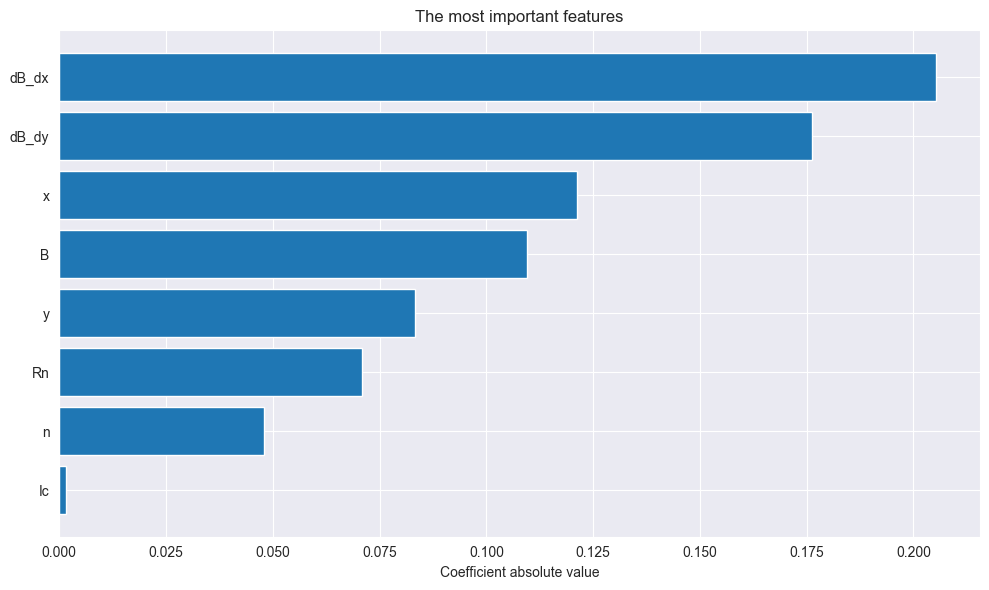

In [240]:
feature_names = poly.get_feature_names_out(features)
coefficients = model.coef_

importance = np.abs(coefficients)

importances_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importance
}).sort_values(by='importance', ascending=False)

top_n = 15
plt.figure(figsize=(10, 6))
plt.barh(importances_df['feature'][:top_n][::-1], importances_df['importance'][:top_n][::-1])
plt.xlabel("Coefficient absolute value")
plt.title("The most important features")
plt.tight_layout()
plt.show()

## Model with only captured map features

In [241]:
df = pd.read_csv("../data/result.csv")
df.head()

,title,x,y,B,dB_dx,dB_dy,Jc,Jx,Jy
0,1,-0.01,0.0,-0.000325,-0.12875,-0.0760,1.090335e+08,7.915898e+07,7.498113e+07
1,1,0.79,0.0,-0.000401,-0.22875,-0.0965,9.263875e+07,8.640185e+06,9.223495e+07
2,1,1.59,0.0,-0.000518,-0.36750,-0.1235,4.150431e+07,3.640487e+07,1.993222e+07
3,1,2.39,0.0,-0.000648,-0.49875,-0.1220,4.602157e+08,-4.334496e+08,-1.546606e+08
4,1,3.19,0.0,-0.000762,-0.70125,-0.0860,1.537920e+09,-1.537311e+09,-4.328145e+07


In [242]:
unique_titles = df['title'].unique()

train_val_titles, test_titles = train_test_split(
    unique_titles, test_size=0.15, random_state=42
)

train_titles, val_titles = train_test_split(
    train_val_titles, test_size=0.1765, random_state=42
)

In [243]:
df['log_Jc'] = np.log10(df['Jc'].replace(0, np.nan))
df_train = df[df['title'].isin(train_titles)]
df_val = df[df['title'].isin(val_titles)]
df_test = df[df['title'].isin(test_titles)]

In [244]:
print(f"Train: {df_train['title'].nunique()} samples, {len(df_train)} rows")
print(f"Validation: {df_val['title'].nunique()} samples, {len(df_val)} rows")
print(f"Test: {df_test['title'].nunique()} samples, {len(df_test)} rows")

Train: 22 samples, 30632 rows
Validation: 5 samples, 6779 rows
Test: 5 samples, 7197 rows


In [245]:
features = ['x', 'y', 'B', 'dB_dx', 'dB_dy']
target = 'log_Jc'

In [246]:
X = df[features]
y = df[target]
groups = df['title']
X_train = df_train[features].values
y_train = df_train[target].values
X_val = df_val[features].values
y_val = df_val[target].values
X_test = df_test[features].values
y_test = df_test[target].values

In [247]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [248]:
poly = PolynomialFeatures(degree=4, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_val_poly = poly.transform(X_val_scaled)
X_test_poly = poly.transform(X_test_scaled)

In [249]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

LinearRegression()

In [250]:
print("Linear regression model evaluation")
evaluate(y_train, model.predict(X_train_poly), "Train")
evaluate(y_val, model.predict(X_val_poly), "Validation")
evaluate(y_test, model.predict(X_test_poly), "Test")

Linear regression model evaluation
Train R²: 0.7564
Train MAE: 2.66e-01
Train RMSE: 3.65e-01
Train MAPE: 3.06e-02

Validation R²: 0.6795
Validation MAE: 3.63e-01
Validation RMSE: 4.68e-01
Validation MAPE: 4.37e-02

Test R²: 0.7748
Test MAE: 2.64e-01
Test RMSE: 3.74e-01
Test MAPE: 3.09e-02



In [251]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=4, include_bias=False)),
    ("model", LinearRegression())
])

scoring = {
    'R2': 'r2',
    'MAE': make_scorer(mean_absolute_error),
    'RMSE': make_scorer(root_mean_squared_error)
}

cv = GroupKFold(n_splits=5)
cv_results = cross_validate(pipeline, X, y, cv=cv, groups=groups,
                            scoring=scoring, return_train_score=True)

In [252]:
print("CV by samples (GroupKFold, degree=4)")
print(f"Train R²:  {np.mean(cv_results['train_R2']):.4f}")
print(f"Valid R²:  {np.mean(cv_results['test_R2']):.4f}")
print(f"Valid MAE: {np.mean(cv_results['test_MAE']):.2e}")
print(f"Valid RMSE:{np.mean(cv_results['test_RMSE']):.2e}")

CV by samples (GroupKFold, degree=4)
Train R²:  0.7661
Valid R²:  0.6086
Valid MAE: 3.16e-01
Valid RMSE:4.67e-01


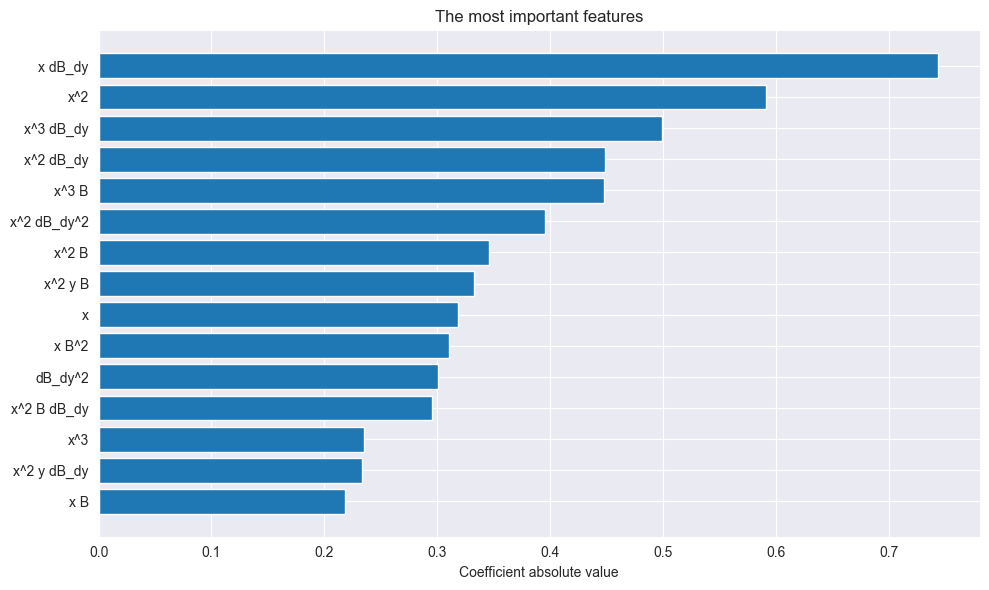

In [253]:
feature_names = poly.get_feature_names_out(features)
coefficients = model.coef_

importance = np.abs(coefficients)

importances_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importance
}).sort_values(by='importance', ascending=False)

top_n = 15
plt.figure(figsize=(10, 6))
plt.barh(importances_df['feature'][:top_n][::-1], importances_df['importance'][:top_n][::-1])
plt.xlabel("Coefficient absolute value")
plt.title("The most important features")
plt.tight_layout()
plt.show()